First 5 rows:
                                               title       price  \
0          600 Yard Bungalow For Sale In DHA Phase 6  11.5 Crore   
1  3 BEDS LUXURY 125 SQ YARDS VILLA FOR SALE LOCA...  1.45 Crore   
2  4 BEDS LUXURY SPORTS CITY VILLA FOR RENT BAHRI...  2.12 Crore   
3  3 BEDS LUXURY 235 SQ YARDS VILLA FOR SALE LOCA...   1.5 Crore   
4                Buying A Flat In Clifton - Block 9?     4 Crore   

     date added   type  bedrooms  bathrooms         area  \
0  14 hours ago  House         5          6  600 Sq. Yd.   
1   5 hours ago  House         0          0          NaN   
2   5 hours ago  House         0          0          NaN   
3   5 hours ago  House         0          0          NaN   
4   6 hours ago   Flat         3          3  200 Sq. Yd.   

                              location  \
0          DHA Defence, Karachi, Sindh   
1  Bahria Town Karachi, Karachi, Sindh   
2  Bahria Town Karachi, Karachi, Sindh   
3  Bahria Town Karachi, Karachi, Sindh   
4     

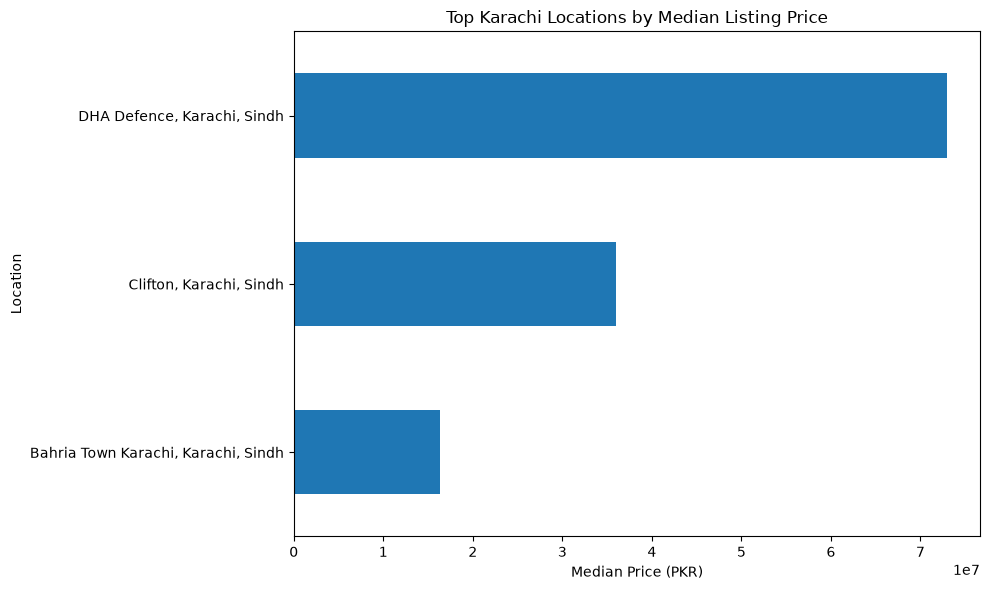

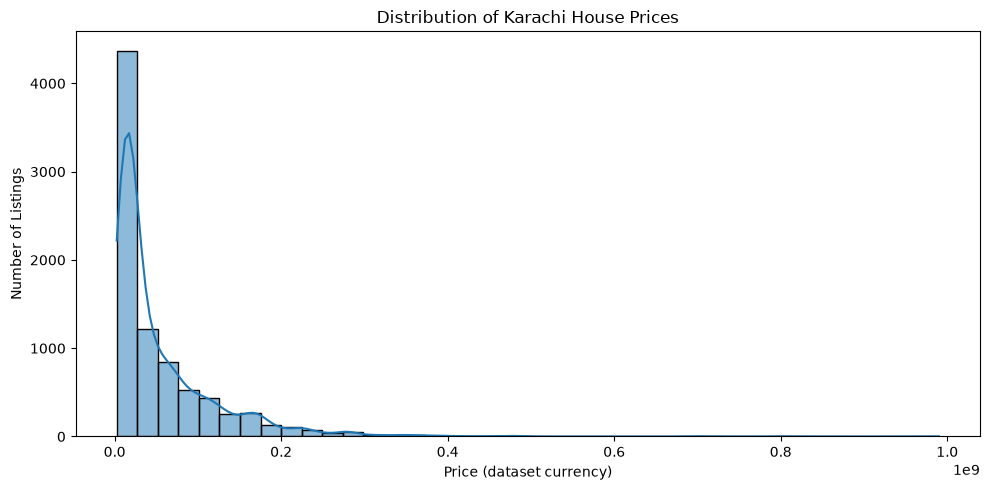

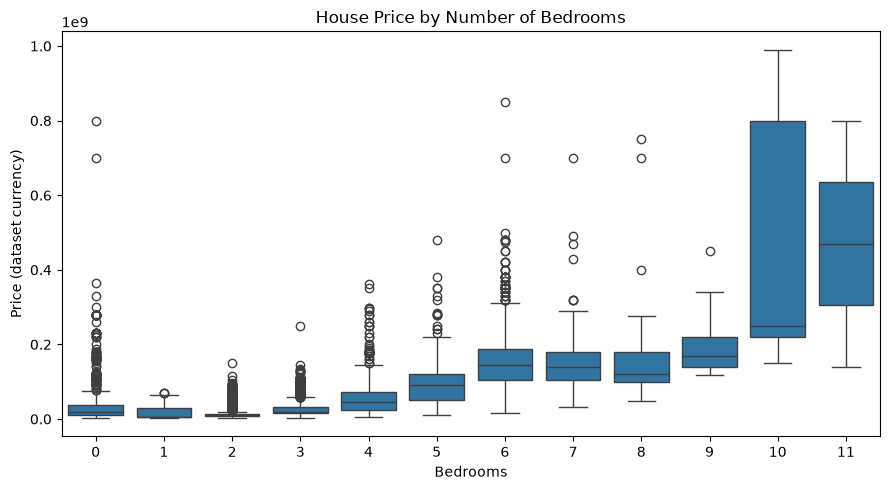

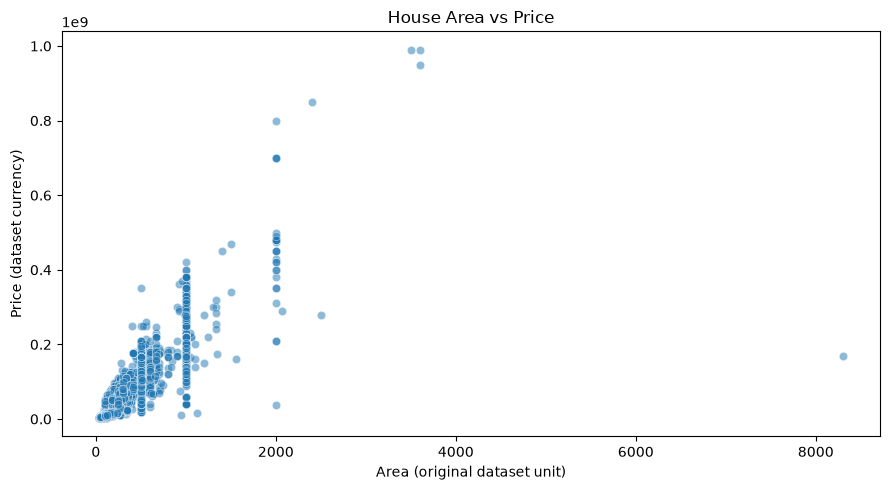

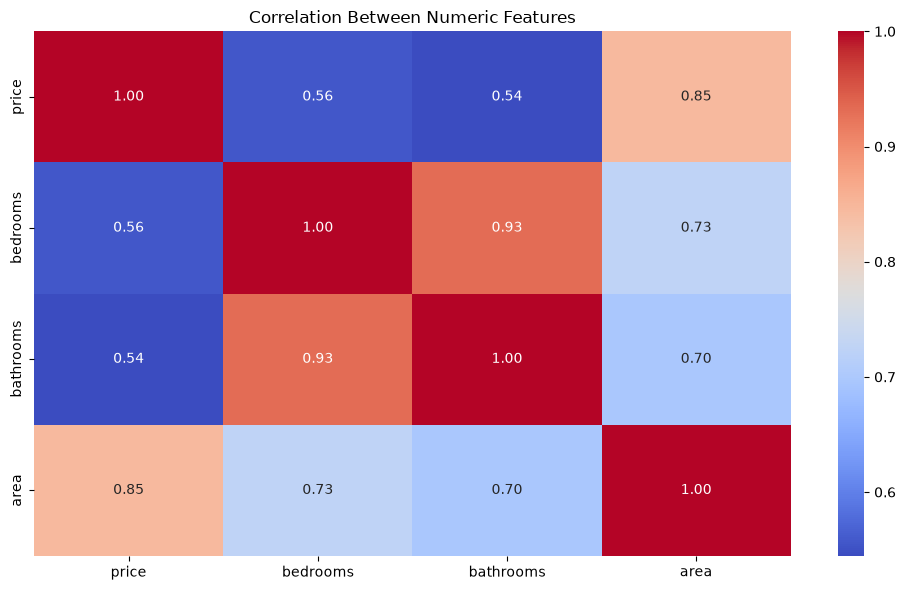


Analysis completed!
Cleaned data saved to: d:\01_Projects\Karachi_House_Price_Project\data\karachi_house_prices_cleaned.csv
Final dataset shape: (8413, 12)


In [ ]:

# =====================================================
# Karachi_House_Price_Project
# Exploratory Data Analysis (EDA)
# Tools: Pandas, NumPy, Matplotlib, Seaborn
# =====================================================

# STEP 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re

# STEP 2: Load dataset
project_root = Path.cwd()
if not (project_root / "data").is_dir() and (project_root.parent / "data").is_dir():
    project_root = project_root.parent
file_path = project_root / "data" / "Karachi.csv"
if not file_path.is_file():
    raise FileNotFoundError(f"Dataset not found: {file_path}")
df = pd.read_csv(file_path)

# STEP 3: Explore the dataset
print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe(include="all"))

# STEP 4: Clean column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# STEP 5: Check missing values and duplicates
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

# STEP 6: Identify important columns
# Adjust these names if your dataset uses different columns.
print("\nAvailable columns:", df.columns.tolist())

# STEP 7: Clean price column
if "price" in df.columns:
    price_parts = df["price"].astype(str).str.extract(
        r"^\s*([\d,]+(?:\.\d+)?)\s*(crore|lakh)\s*$",
        flags=re.IGNORECASE
    )
    price_amount = pd.to_numeric(
        price_parts[0].str.replace(",", "", regex=False), errors="coerce"
    )
    price_multiplier = price_parts[1].str.lower().map(
        {"crore": 10_000_000, "lakh": 100_000}
    )
    df["price"] = price_amount * price_multiplier

    df = df.dropna(subset=["price"])
    df = df[df["price"] > 0]

# STEP 8: Clean bedrooms and area where available
if "bedrooms" in df.columns:
    df["bedrooms"] = pd.to_numeric(
        df["bedrooms"], errors="coerce"
    )

if "area" in df.columns:
    area_values = df["area"].astype(str).str.extract(r"([\d,]+(?:\.\d+)?)")[0]
    df["area"] = pd.to_numeric(
        area_values.str.replace(",", "", regex=False), errors="coerce"
    )

# STEP 9: Basic analysis
if "price" in df.columns:
    print("\nAverage house price:", df["price"].mean())
    print("Median house price:", df["price"].median())
    print("Minimum house price:", df["price"].min())
    print("Maximum house price:", df["price"].max())

# STEP 10: Top locations by listing count
location_col = next(
    (c for c in ["location", "area_name", "area_category"]
     if c in df.columns),
    None
)

if location_col:
    print("\nTop 10 locations by number of listings:")
    print(df[location_col].value_counts().head(10))

# STEP 11: Average price by location
if location_col and "price" in df.columns:
    location_prices = (
        df.groupby(location_col)["price"]
        .agg(["mean", "median", "count"])
        .query("count >= 5")
        .sort_values("median", ascending=False)
        .head(10)
    )

    print("\nTop locations by median price:")
    print(location_prices)

    if not location_prices.empty:
        location_prices["median"].sort_values().plot(
            kind="barh", figsize=(7, 3.5)
        )
        plt.title("Top Karachi Locations by Median Listing Price")
        plt.xlabel("Median Price (PKR)")
        plt.ylabel("Location")
        plt.tight_layout()
        plt.show()

# STEP 12: House price distribution
if "price" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df["price"], bins=40, kde=True)
    plt.title("Distribution of Karachi House Prices")
    plt.xlabel("Price (dataset currency)")
    plt.ylabel("Number of Listings")
    plt.tight_layout()
    plt.show()

# STEP 13: Bedrooms vs price
if "bedrooms" in df.columns and "price" in df.columns:
    bedroom_prices = df.dropna(
        subset=["bedrooms", "price"]
    )

    plt.figure(figsize=(7, 4))
    sns.boxplot(
        data=bedroom_prices,
        x="bedrooms",
        y="price"
    )
    plt.title("House Price by Number of Bedrooms")
    plt.xlabel("Bedrooms")
    plt.ylabel("Price (dataset currency)")
    plt.tight_layout()
    plt.show()

# STEP 14: Area vs price
if "area" in df.columns and "price" in df.columns:
    area_prices = df.dropna(subset=["area", "price"])

    plt.figure(figsize=(7, 4))
    sns.scatterplot(
        data=area_prices,
        x="area",
        y="price",
        alpha=0.5
    )
    plt.title("House Area vs Price")
    plt.xlabel("Area (original dataset unit)")
    plt.ylabel("Price (dataset currency)")
    plt.tight_layout()
    plt.show()

# STEP 15: Correlation heatmap
numeric_df = df.select_dtypes(include=np.number)

if len(numeric_df.columns) >= 2:
    plt.figure(figsize=(7, 4.5))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Between Numeric Features")
    plt.tight_layout()
    plt.show()

# STEP 16: Save cleaned dataset
output_path = project_root / "data" / "karachi_house_prices_cleaned.csv"
df.to_csv(output_path, index=False)

print("\nAnalysis completed!")
print("Cleaned data saved to:", output_path)
print("Final dataset shape:", df.shape)
